# Does a sequence of matching windows identify a song more reliably?

We compare the strongest individual match and time-offset voting on the same 18 seconds of audio. Both methods receive the same three MuQ windows, the same top 12 candidate reference windows per query window, and the same exact cosine search on FMA medium. The fixed tolerance is three seconds, allowing for a reference grid spaced five seconds apart. The benchmark uses synthetic controls; a physical phone-capture protocol is [available separately](../reports/temporal-study.md).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"reports/temporal-controls.csv").exists())
rows = pd.read_csv(root/"reports/temporal-controls.csv")
assert rows.track_id.nunique() == 128 and len(rows) == 384
assert not rows.duplicated(["track_id","condition"]).any()
assert rows.support_windows.between(1,3).all()
for method in ("strongest","temporal"):
    rows[method+"_correct"] = rows[method] == rows.track_id
rates = rows.groupby("condition")[["strongest_correct","temporal_correct"]].mean()
display(rates.round(4))

,strongest_correct,temporal_correct
condition,,
direct,0.9922,0.9844
room_noise,0.9844,0.9766
speed_voice_mp3,0.8438,0.8750


## Paired changes

Improved clips switch from an incorrect to a correct track. Regressions switch the other way. The overall confidence interval resamples songs with all their conditions together. An interval containing zero leaves the direction of the effect unresolved on this sample.

In [2]:
rows["improved"] = ~rows.strongest_correct & rows.temporal_correct
rows["regressed"] = rows.strongest_correct & ~rows.temporal_correct
rows["difference"] = rows.temporal_correct.astype(int) - rows.strongest_correct.astype(int)
delta = rows.groupby("track_id").difference.mean().to_numpy()
means = np.random.default_rng(422).choice(delta,size=(5000,len(delta))).mean(axis=1)
summary = rows.groupby("condition")[["improved","regressed"]].sum()
display(summary)
print("Overall difference (percentage points) and 95% paired track-bootstrap interval:",
      np.round(100*np.r_[delta.mean(),np.quantile(means,[.025,.975])],2))
timing = json.loads((root/"reports/temporal-controls-timing.json").read_text())
display(pd.DataFrame(timing).T.round(2))

,improved,regressed
condition,,
direct,0,1
room_noise,0,1
speed_voice_mp3,7,3


Overall difference (percentage points) and 95% paired track-bootstrap interval: [ 0.52 -1.56  2.34]


,median_ms,p95_ms,n
strongest,35.37,36.44,24.0
temporal,35.50,36.79,24.0


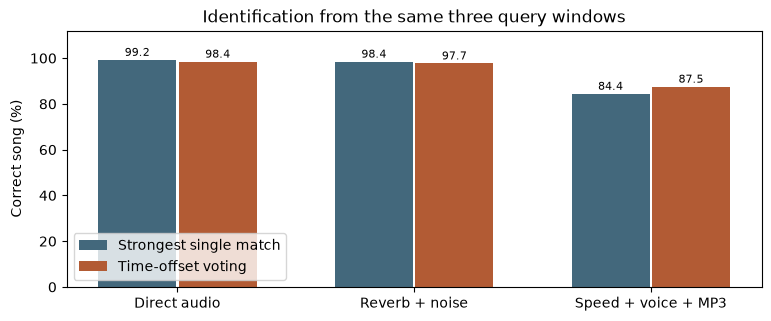

In [3]:
fig,ax=plt.subplots(figsize=(7.6,3.1),layout="constrained")
labels={"direct":"Direct audio","room_noise":"Reverb + noise","speed_voice_mp3":"Speed + voice + MP3"}
x=np.arange(len(rates))
for offset,column,label,color in [(-.17,"strongest_correct","Strongest single match","#43687c"),
                                   (.17,"temporal_correct","Time-offset voting","#b25b34")]:
    bars=ax.bar(x+offset,rates[column]*100,width=.33,label=label,color=color)
    ax.bar_label(bars,fmt="%.1f",fontsize=8,padding=1)
ax.set(xticks=x,xticklabels=[labels[v] for v in rates.index],ylim=(0,112),ylabel="Correct song (%)")
ax.legend(loc="lower left")
ax.set_title("Identification from the same three query windows")
fig.savefig(root/"reports/figures/temporal-voting.pdf",bbox_inches="tight")
plt.show()

## Optional physical recordings

Physical-phone results use a separate manifest and are shown only after the phone scorer has processed actual capture files.

In [4]:
phone_csv = root / "data/medium/phone-study/results/temporal-phone.csv"
if phone_csv.exists():
    captures = pd.read_csv(phone_csv)
    matches = captures.assign(strongest_correct=captures.strongest == captures.track_id,
                              temporal_correct=captures.temporal == captures.track_id)
    display(matches.groupby("condition").agg(captures=("track_id","size"), songs=("track_id","nunique"),
            strongest_accuracy=("strongest_correct","mean"), temporal_accuracy=("temporal_correct","mean")))
else:
    print("Physical capture pending. All results above are digital controls.")

Physical capture pending. All results above are digital controls.
